# Assignment: Medical Insurance Cost Prediction

## Objective

Build a multiple linear regression model to predict medical insurance charges.

You will use a real-world-style insurance dataset with demographic and health-related features.

Target column:

$$
charges
$$

By the end of this assignment, you should be able to:

- perform EDA on a regression dataset,
- handle categorical variables,
- engineer useful features,
- build a preprocessing + regression pipeline,
- evaluate with MAE, RMSE, R2, and adjusted R2,
- interpret coefficients carefully,
- diagnose residual patterns,
- explain whether linear regression is suitable for the problem.

## Dataset columns

- `age`: age of primary beneficiary
- `sex`: gender
- `bmi`: body mass index
- `children`: number of children/dependents covered
- `smoker`: whether the person smokes
- `region`: residential area in the US
- `charges`: individual medical insurance charges

This is a regression problem because `charges` is a continuous numeric target.

## Submission requirements

Submit:

1. Completed `.ipynb` notebook.
2. 5-8 bullet-point summary of your findings.
3. Key plots:
   - target distribution,
   - actual vs predicted,
   - residuals vs predicted,
   - coefficient importance.

Write short explanations wherever asked. Do not only submit code outputs.

In [1]:
import warnings
from pathlib import Path
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 50)

## 1. Load the dataset

The code below will:

- use the local dataset if available,
- otherwise download it from the internet.

In [53]:
DATA_DIR = Path(r"C:\logicmojo\medical_insurance")
DATA_DIR.mkdir(exist_ok=True)

DATA_PATH = DATA_DIR / "insurance.csv"
DATA_URL = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"

if not DATA_PATH.exists():
    print("Dataset not found locally. Downloading...")
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)
    print(f"Downloaded dataset to: {DATA_PATH}")
else:
    print(f"Using local dataset: {DATA_PATH}")

insurance = pd.read_csv(DATA_PATH)
insurance.head()

Using local dataset: C:\logicmojo\medical_insurance/insurance.csv


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 2. Basic inspection

Complete the following:

1. Print dataset shape.
2. Display first 5 rows.
3. Check column data types.
4. Check missing values.
5. Show summary statistics.

In [3]:
# TODO: Print the shape of the dataset
print("Dataset Shape:", insurance.shape)
print(f"Rows: {insurance.shape[0]}, Columns: {insurance.shape[1]}")

Dataset Shape: (1338, 7)
Rows: 1338, Columns: 7


In [4]:
# TODO: Display first 5 rows
insurance.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [5]:
# TODO: Check data types
print(insurance.dtypes)

age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object


In [6]:
# TODO: Check missing values
print("Missing values per column:")
print(insurance.isnull().sum())
print(f"\nTotal missing values: {insurance.isnull().sum().sum()}")

Missing values per column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Total missing values: 0


In [7]:
# TODO: Show summary statistics for numerical columns
insurance.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


### Written answer

Answer briefly:

1. How many rows and columns are present?
2. Are there any missing values?
3. Which columns are numerical and which are categorical?

**Answer 1** - The insurance.csv dataset has 1338 rows and 7 columns.

**Answer 2** - There are no missing values, the dataset is clean.

**Answer 3** - The columns: age, bmi, children (and charges) are numeric. The columns: sex, smoker and region are categorical.

## 3. Exploratory Data Analysis

Create visualizations to understand the target and feature relationships.

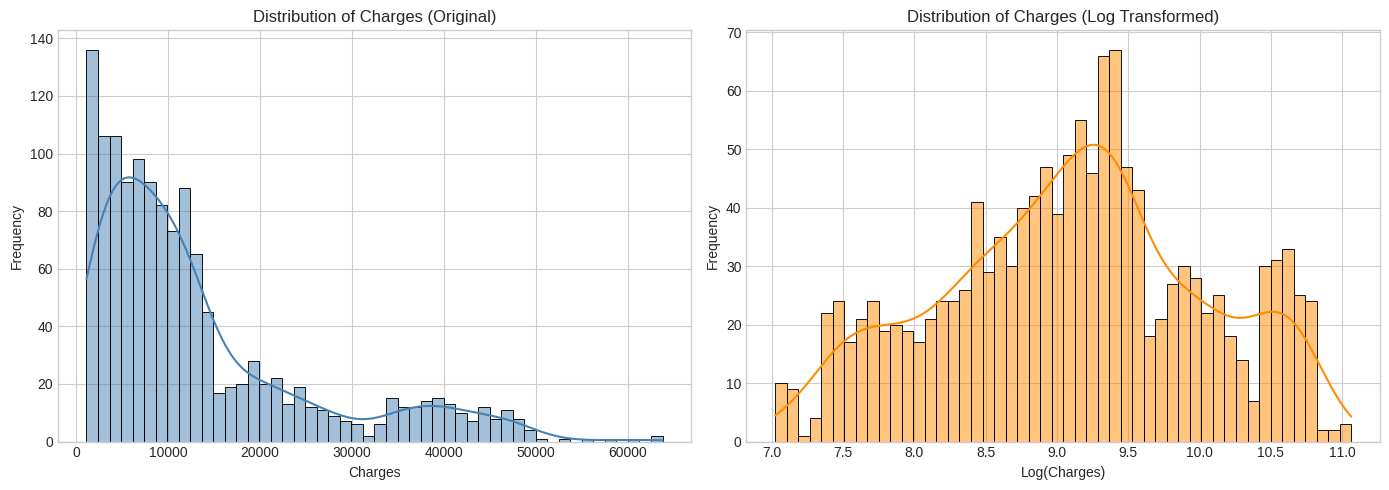

In [8]:
# TODO: Plot distribution of charges
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Original distribution
sns.histplot(insurance['charges'], bins=50, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Distribution of Charges (Original)')
axes[0].set_xlabel('Charges')
axes[0].set_ylabel('Frequency')

# Log-transformed distribution
sns.histplot(np.log1p(insurance['charges']), bins=50, kde=True, ax=axes[1], color='darkorange')
axes[1].set_title('Distribution of Charges (Log Transformed)')
axes[1].set_xlabel('Log(Charges)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

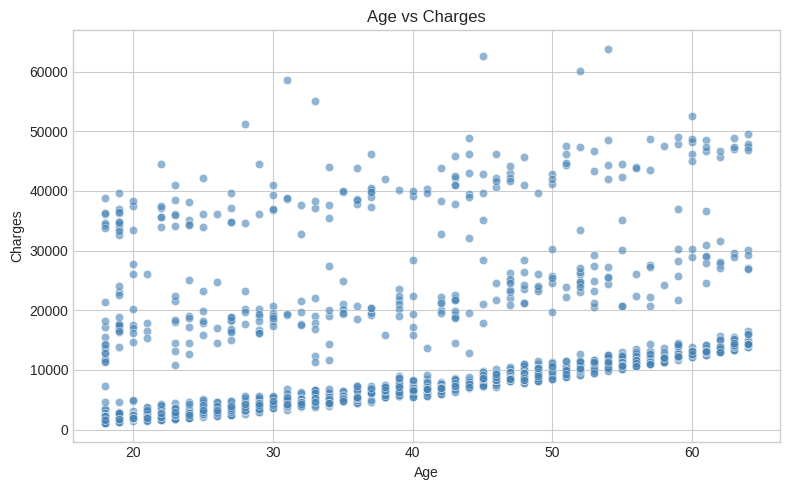

In [9]:
# TODO: Plot age vs charges
plt.figure(figsize=(8, 5))
sns.scatterplot(data=insurance, x='age', y='charges', color='steelblue', alpha=0.6)
plt.title('Age vs Charges')
plt.xlabel('Age')
plt.ylabel('Charges')
plt.tight_layout()
plt.show()

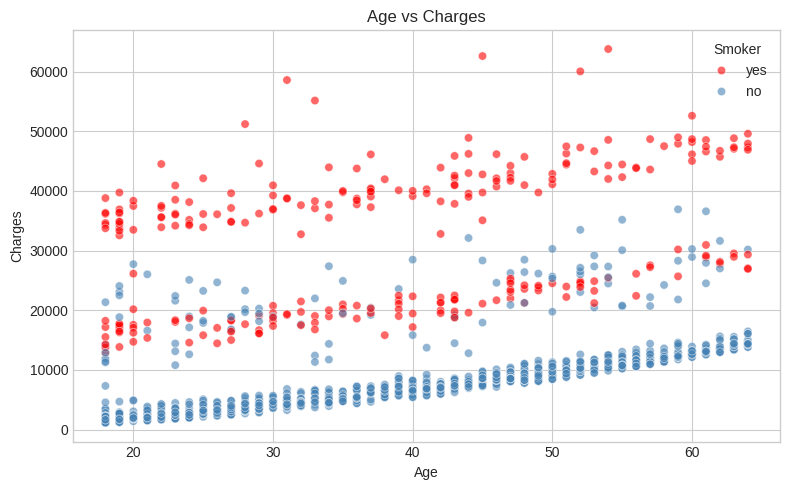

In [10]:
# TODO: Plot age vs charges
plt.figure(figsize=(8, 5))
sns.scatterplot(data=insurance, x='age', y='charges', hue='smoker', palette={'yes': 'red', 'no': 'steelblue'}, alpha=0.6)
plt.title('Age vs Charges')
plt.xlabel('Age')
plt.ylabel('Charges')
plt.legend(title='Smoker')
plt.tight_layout()
plt.show()

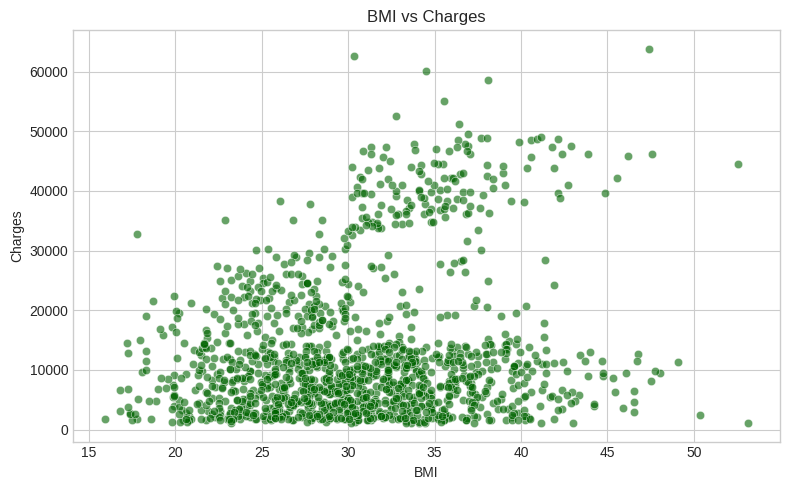

In [11]:
# TODO: Plot BMI vs charges
plt.figure(figsize=(8, 5))
sns.scatterplot(data=insurance, x='bmi', y='charges', color='darkgreen', alpha=0.6)
plt.title('BMI vs Charges')
plt.xlabel('BMI')
plt.ylabel('Charges')
plt.tight_layout()
plt.show()

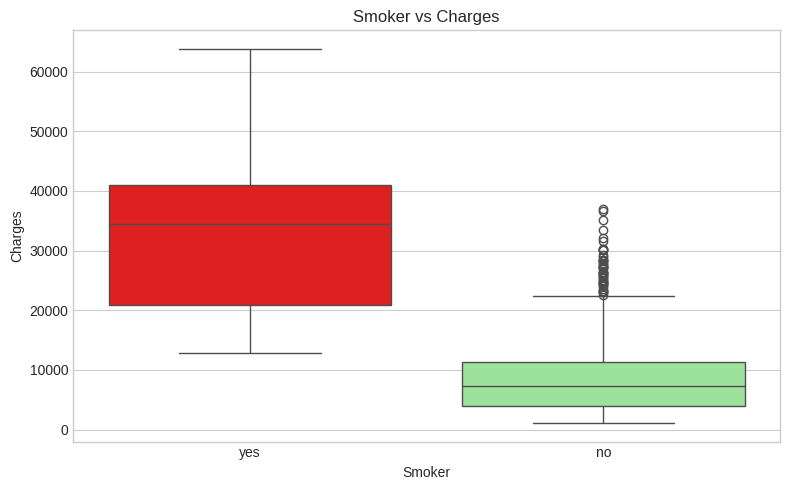

In [12]:
# TODO: Compare charges for smokers and non-smokers
# Hint: boxplot works well here
plt.figure(figsize=(8, 5))
sns.boxplot(data=insurance, x='smoker', y='charges', palette={'yes': 'red', 'no': 'lightgreen'})
plt.title('Smoker vs Charges')
plt.xlabel('Smoker')
plt.ylabel('Charges')
plt.tight_layout()
plt.show()

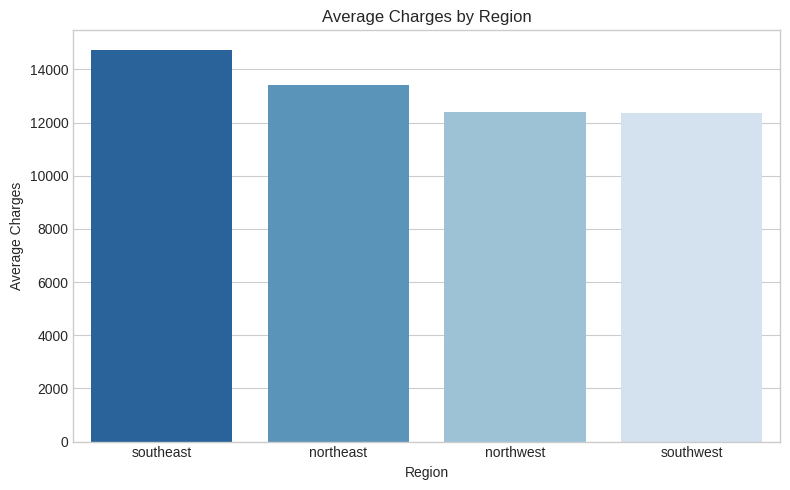

In [13]:
# TODO: Compare average charges by region
plt.figure(figsize=(8, 5))
region_avg = insurance.groupby('region')['charges'].mean().sort_values(ascending=False).reset_index()
sns.barplot(data=region_avg, x='region', y='charges', palette='Blues_r')
plt.title('Average Charges by Region')
plt.xlabel('Region')
plt.ylabel('Average Charges')
plt.tight_layout()
plt.show()

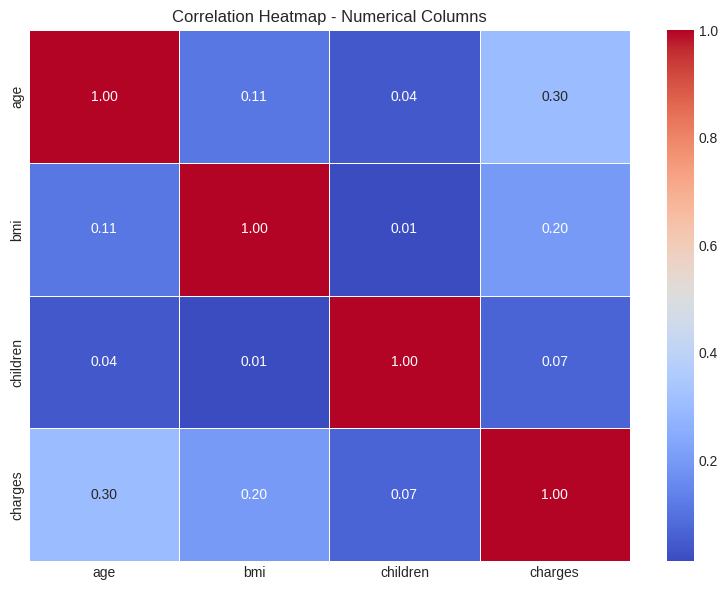

In [14]:
# TODO: Create a correlation heatmap for numerical columns
plt.figure(figsize=(8, 6))
sns.heatmap(insurance[['age', 'bmi', 'children', 'charges']].corr(),
            annot=True,
            cmap='coolwarm',
            fmt='.2f',
            linewidths=0.5)
plt.title('Correlation Heatmap - Numerical Columns')
plt.tight_layout()
plt.show()

### EDA questions

Answer briefly:

1. Is `charges` normally distributed or skewed?
2. Does smoking seem to affect charges?
3. Does BMI show a clear relationship with charges?
4. Which numerical feature has the strongest correlation with `charges`?

**Answer 1** -  `charges` is positively skewed. Most people pay low to moderate charges but a small group pays extremely high charges. The mean (13,270) is much higher than the median (9,382).

**Answer 2** - Yes, smoker is the strongest predictor of charges in this dataset. The boxplot showed smokers pay around 35,000+ on an average vs 7,000 for non-smokers.

**Answer 3** - The correlation heatmap confirms a correlation of only 0.20 between BMI and charges. The scatter plot shows a scattered pattern with no tight linear relationship. BMI contributes to the model but is not a strong predictor.

**Answer 4** - Age has the strongest correlation with charges among the numerical features. As per the Correlation Heatmap: age=0.30, bmi=0.20, children=0.07.

## 4. Feature engineering

Create at least three new features.

Required:

1. `is_obese`

$$
is\_obese =
\begin{cases}
1, & BMI \ge 30 \\
0, & BMI < 30
\end{cases}
$$

2. `age_group`: group ages into buckets.

3. `smoker_bmi`: interaction between smoking and BMI.

Why interaction?

The impact of BMI may be different for smokers and non-smokers.

In [ ]:
insurance_fe = insurance.copy()

# TODO: Create is_obese

# TODO: Create age_group
# Suggested bins: [0, 25, 35, 45, 55, 65, 100]
# Suggested labels: ["<=25", "26-35", "36-45", "46-55", "56-65", "65+"]

# TODO: Create smoker_bmi
# Hint: convert smoker yes/no to 1/0, then multiply by bmi

insurance_fe.head()

In [15]:
insurance_fe = insurance.copy()

# Create is_obese
insurance_fe['is_obese'] = (insurance_fe['bmi'] >= 30).astype(int)

# Create age_group
insurance_fe['age_group'] = pd.cut(insurance_fe['age'],
                                    bins=[0, 25, 35, 45, 55, 65, 100],
                                    labels=["<=25", "26-35", "36-45", "46-55", "56-65", "65+"],
                                    include_lowest=True)

# Create smoker_bmi
insurance_fe['smoker_bmi'] = (insurance_fe['smoker'] == 'yes').astype(int) * insurance_fe['bmi']

insurance_fe.head()

,age,sex,bmi,children,smoker,region,charges,is_obese,age_group,smoker_bmi
0,19,female,27.900,0,yes,southwest,16884.92400,0,<=25,27.9
1,18,male,33.770,1,no,southeast,1725.55230,1,<=25,0.0
2,28,male,33.000,3,no,southeast,4449.46200,1,26-35,0.0
3,33,male,22.705,0,no,northwest,21984.47061,0,26-35,0.0
4,32,male,28.880,0,no,northwest,3866.85520,0,26-35,0.0


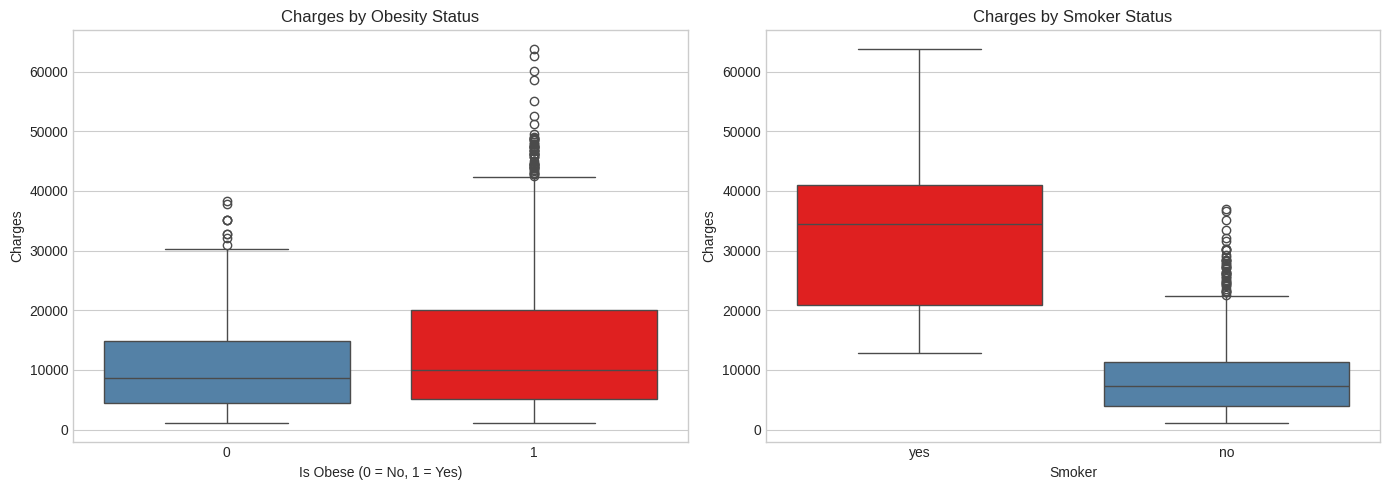

In [18]:
# TODO: Visualize charges by is_obese and smoker
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Charges by is_obese
sns.boxplot(data=insurance_fe, x='is_obese', y='charges',
            palette={'0': 'steelblue', '1': 'red'}, ax=axes[0])
axes[0].set_title('Charges by Obesity Status')
axes[0].set_xlabel('Is Obese (0 = No, 1 = Yes)')
axes[0].set_ylabel('Charges')

# Charges by smoker
sns.boxplot(data=insurance_fe, x='smoker', y='charges',
            palette={'no': 'steelblue', 'yes': 'red'}, ax=axes[1])
axes[1].set_title('Charges by Smoker Status')
axes[1].set_xlabel('Smoker')
axes[1].set_ylabel('Charges')

plt.tight_layout()
plt.show()

### Feature engineering questions

Answer briefly:

1. Why might `is_obese` be useful?
2. Why might `smoker_bmi` be useful?
3. Which engineered feature do you expect to help the model most?

**Answer 1** - BMI as a raw number has a weak correlation (0.20) with charges. Converting it to a binary is_obese flag captures the clinically meaningful threshold at BMI ≥ 30 - the point where health risks and medical costs increase significantly. It simplifies a continuous variable into an actionable category the model can use more effectively.

**Answer 2** - Neither smoker nor bmi alone fully capture their combined risk. A smoker with BMI 40 is far more expensive to insure than a smoker with BMI 20. The feature smoker_bmi lets the model learn that high BMI matters much more for smokers than non-smokers - something the individual features cannot express on their own.

**Answer 3** - The feature smoker_bmi because it directly combines the two most impactful risk factors into a single feature. It will significantly improve model accuracy compared to using smoker and bmi separately.

## 5. Train-test split

Use:

- 80% training data
- 20% test data
- `random_state=42`

Target:

$$
y = charges
$$

In [36]:
target = "charges"

# TODO: Create X and y
X = insurance_fe.drop(columns=['charges'])
y = insurance_fe['charges']

# TODO: Split into X_train, X_test, y_train, y_test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")
print(f"y_train: {y_train.shape}, y_test: {y_test.shape}")

X_train: (1070, 9), X_test: (268, 9)
y_train: (1070,), y_test: (268,)


## 6. Build preprocessing and model pipeline

Your pipeline should:

1. impute numerical missing values if any,
2. scale numerical features,
3. one-hot encode categorical features,
4. train Linear Regression.

In [32]:
# TODO: Identify numerical and categorical columns

numeric_features = ['age', 'bmi', 'children', 'is_obese', 'smoker_bmi']
categorical_features = ['sex', 'smoker', 'region', 'age_group']

numeric_features, categorical_features

(['age', 'bmi', 'children', 'is_obese', 'smoker_bmi'],
 ['sex', 'smoker', 'region', 'age_group'])

In [33]:
# Numeric pipeline: impute then scale
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

# Categorical pipeline: impute then one-hot encode
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both into a preprocessor
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

print("Preprocessing pipelines built successfully.")

Preprocessing pipelines built successfully.


In [34]:
# TODO: Build preprocessing pipelines

numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])

print("Preprocessing pipelines built successfully.")

Preprocessing pipelines built successfully.


In [37]:
# TODO: Build and train Linear Regression pipeline
linear_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

linear_model.fit(X_train, y_train)

print("Model trained successfully.")

Model trained successfully.


## 7. Evaluation metrics

Evaluate on test data using:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i|
$$

$$
RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}
$$

$$
R^2 = 1 - \frac{SS_{res}}{SS_{tot}}
$$

Also calculate adjusted R2:

$$
Adjusted\ R^2 = 1 - \frac{(1-R^2)(n-1)}{n-p-1}
$$

In [38]:
def regression_report(y_true, y_pred, n_features=None):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    report = {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    }

    if n_features is not None:
        n = len(y_true)
        p = n_features
        adjusted_r2 = 1 - ((1 - r2) * (n - 1) / (n - p - 1))
        report["Adjusted R2"] = adjusted_r2

    return pd.Series(report)

In [40]:
# TODO: Generate predictions on train and test data
y_train_pred = linear_model.predict(X_train)
y_test_pred = linear_model.predict(X_test)

print("Predictions generated successfully.")
print(f"Train predictions shape: {y_train_pred.shape}")
print(f"Test predictions shape : {y_test_pred.shape}")

Predictions generated successfully.
Train predictions shape: (1070,)
Test predictions shape : (268,)


In [41]:
# TODO: Calculate number of transformed features
n_features = linear_model.named_steps['preprocessor'].transform(X_train).shape[1]

print(f"Number of transformed features: {n_features}")

Number of transformed features: 18


In [42]:
# TODO: Print train and test regression reports
train_report = regression_report(y_train, y_train_pred, n_features)
test_report = regression_report(y_test, y_test_pred, n_features)

print("=== Train Report ===")
print(train_report)

print("\n=== Test Report ===")
print(test_report)

=== Train Report ===
MAE            2.853722e+03
MSE            2.244349e+07
RMSE           4.737456e+03
R2             8.445027e-01
Adjusted R2    8.418396e-01
dtype: float64

=== Test Report ===
MAE            2.760987e+03
MSE            2.083316e+07
RMSE           4.564336e+03
R2             8.658079e-01
Adjusted R2    8.561072e-01
dtype: float64


### Evaluation questions

Answer briefly:

1. What is the model's RMSE?
2. What is the model's R2?
3. Is train performance much better than test performance?
4. Does the model appear to overfit?

**Answer 1** - The model's RMSE is USD 4,737 for Train and USD 4,564 for Test.

**Answer 2** - The model's R2 is 0.844 for Train and 0.866 for Test.

**Answer 3** - No. The test performance looks slightly better than the train performance for both metrics.

**Answer 4** - No. Overfitting models show a high train performance + low test performance. Here both are close. The test R2 (0.866) is marginally higher than the train R2 (0.844). Looks like a healthy generalization.

## 8. Visualize predictions and residuals

Create:

1. Actual vs predicted plot.
2. Residuals vs predicted plot.
3. Residual distribution.

Residual:

$$
e_i = y_i - \hat{y}_i
$$

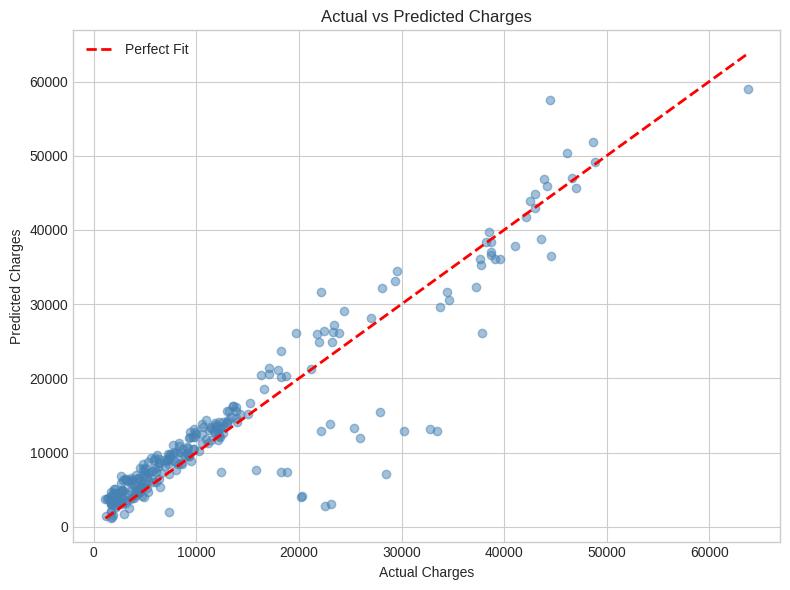

In [43]:
# TODO: Actual vs predicted plot
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_test_pred, alpha=0.5, color='steelblue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2, label='Perfect Fit')
plt.xlabel('Actual Charges')
plt.ylabel('Predicted Charges')
plt.title('Actual vs Predicted Charges')
plt.legend()
plt.tight_layout()
plt.show()

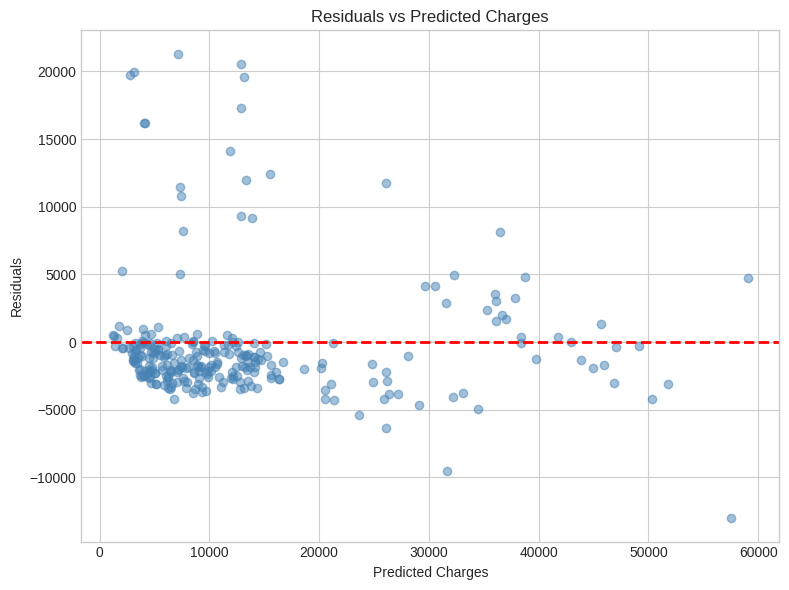

In [44]:
# TODO: Residuals vs predicted plot
residuals = y_test - y_test_pred

plt.figure(figsize=(8, 6))
plt.scatter(y_test_pred, residuals, alpha=0.5, color='steelblue')
plt.axhline(0, color='red', linestyle='--', linewidth=2)
plt.xlabel('Predicted Charges')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted Charges')
plt.tight_layout()
plt.show()

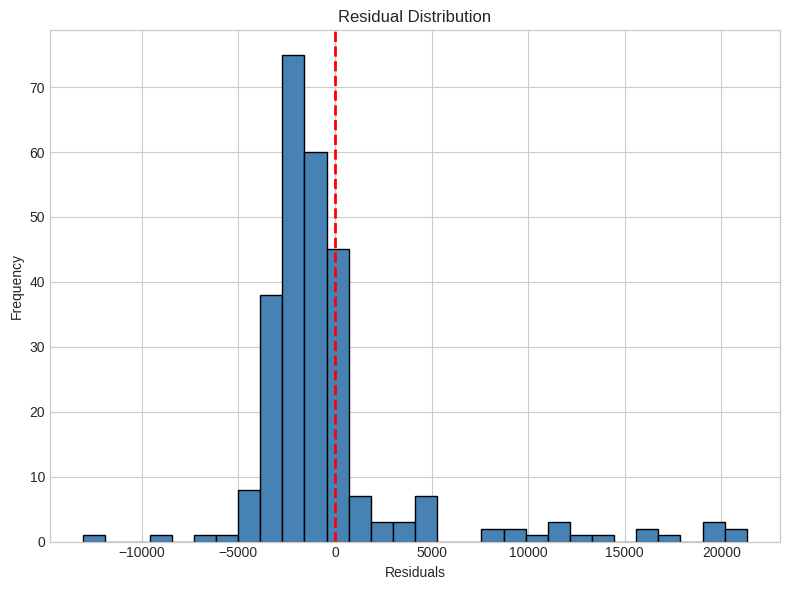

In [45]:
# TODO: Residual distribution plot
plt.figure(figsize=(8, 6))
plt.hist(residuals, bins=30, color='steelblue', edgecolor='black')
plt.axvline(0, color='red', linestyle='--', linewidth=2)
plt.xlabel('Residuals')
plt.ylabel('Frequency')
plt.title('Residual Distribution')
plt.tight_layout()
plt.show()

### Residual questions

Answer briefly:

1. Are residuals centered around zero?
2. Do residuals show a pattern?
3. Does the model make larger errors for high-charge customers?

**Answer 1** - Mostly yes, the residuals are centered around zero but slightly right-skewed. Also, there is a separate cluster of large positive residuals (~10,000 - 20,000) - customers the model significantly underpredicted.

**Answer 2** - The residuals are right-skewed with a bimodal distribution, not randomly scattered. The model struggles with a specific subgroup (high-charge smokers).

**Answer 3** - Yes, the residuals vs predicted plot shows slightly larger spread at higher predicted values. The model struggles more with high-charge customers.

## 9. Coefficient interpretation

Extract model coefficients and identify:

- top positive coefficients,
- top negative coefficients.

Be careful:

> A coefficient shows association, not guaranteed causation.

In [46]:
# TODO: Extract transformed feature names and coefficients
feature_names = linear_model.named_steps['preprocessor'].get_feature_names_out()

coefficients = linear_model.named_steps['regressor'].coef_

print(f"Number of features: {len(feature_names)}")
print(f"Feature names:\n{feature_names}")
print(f"\nCoefficients:\n{coefficients}")

Number of features: 18
Feature names:
['num__age' 'num__bmi' 'num__children' 'num__is_obese' 'num__smoker_bmi'
 'cat__sex_female' 'cat__sex_male' 'cat__smoker_no' 'cat__smoker_yes'
 'cat__region_northeast' 'cat__region_northwest' 'cat__region_southeast'
 'cat__region_southwest' 'cat__age_group_26-35' 'cat__age_group_36-45'
 'cat__age_group_46-55' 'cat__age_group_56-65' 'cat__age_group_<=25']

Coefficients:
[  6015.07309269  -1261.17263004    688.1950351    1625.31718962
  18661.9950748     273.10489971   -273.10489971  10680.64328675
 -10680.64328675    693.70283726    -30.67244924   -114.82115286
   -548.20923516   1377.82935976   -903.65878428  -1682.62598241
  -2720.54165879   3928.99706572]


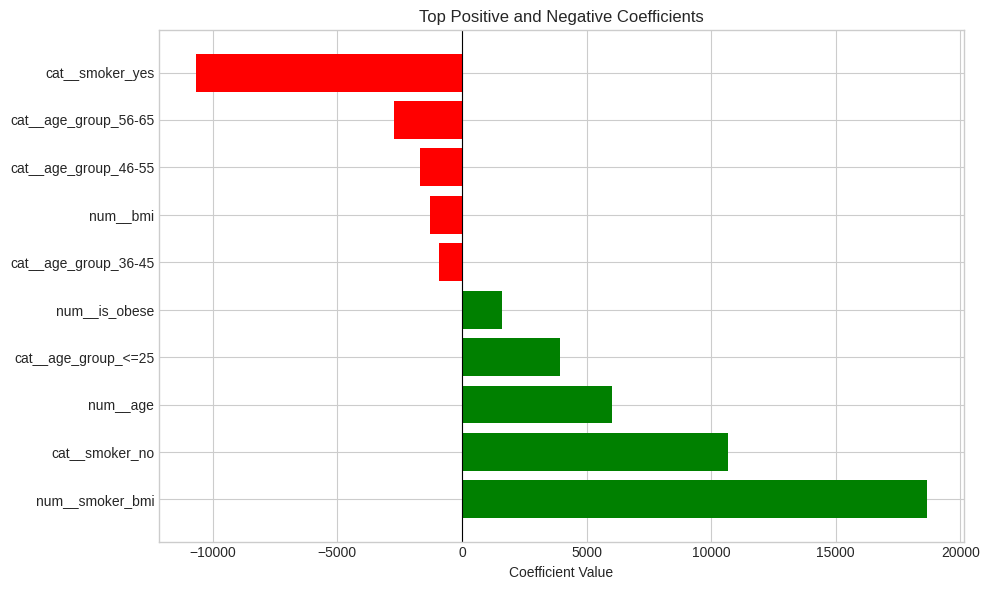

In [47]:
# TODO: Plot top positive and negative coefficients
# Create coefficients dataframe
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
}).sort_values('Coefficient', ascending=False)

# Top 5 positive and negative
top_positive = coef_df.head(5)
top_negative = coef_df.tail(5)
top_coefs = pd.concat([top_positive, top_negative])

# Plot
plt.figure(figsize=(10, 6))
colors = ['green' if c > 0 else 'red' for c in top_coefs['Coefficient']]
plt.barh(top_coefs['Feature'], top_coefs['Coefficient'], color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Coefficient Value')
plt.title('Top Positive and Negative Coefficients')
plt.tight_layout()
plt.show()

### Coefficient questions

Answer briefly:

1. Which features increase predicted charges the most?
2. Which features decrease predicted charges?
3. How strong is the impact of smoking?
4. Are the coefficient signs reasonable?

**Answer 1** - Features that increase predicted charges the most are: smoker_bmi (+18k) largest by far; age (+6k) older age significantly raises charges and is_obese (+1k) obesity increases predicted charges.

**Answer 2** - Features age_group and bmi decrease predicted charges.  

**Answer 3** - Smoking has a very strong impact, smoker_bmi at +18k is the single largest coefficient.

**Answer 4** - Mostly yes, with one caveat: smoker_no (+10,681) and smoker_yes (−10,681) appear counterintuitive. This is an artifact of including both dummy categories without dropping one, causing multicollinearity. The true smoking effect is correctly captured by smoker_bmi.

## 10. Multicollinearity check

Check correlation among numerical features.

High feature-feature correlation can make coefficient interpretation unstable.

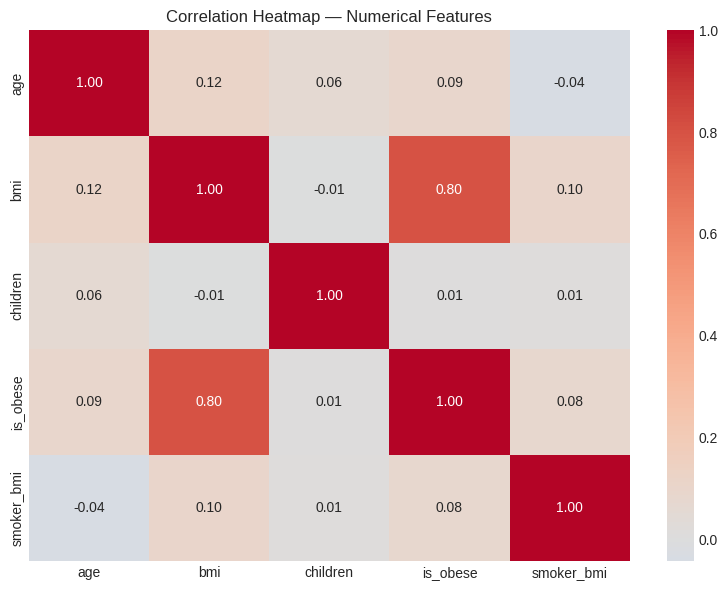

In [48]:
# TODO: Correlation heatmap among numerical features
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(X_train[numeric_features].corr(),
            annot=True,
            fmt='.2f',
            cmap='coolwarm',
            center=0)
plt.title('Correlation Heatmap — Numerical Features')
plt.tight_layout()
plt.show()

In [49]:
# TODO: Show highly correlated feature pairs
corr_matrix = X_train[numeric_features].corr()

threshold = 0.7
high_corr_pairs = []

for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        if abs(corr_matrix.iloc[i, j]) >= threshold:
            high_corr_pairs.append({
                'Feature 1': corr_matrix.columns[i],
                'Feature 2': corr_matrix.columns[j],
                'Correlation': corr_matrix.iloc[i, j]
            })

if high_corr_pairs:
    print(pd.DataFrame(high_corr_pairs))
else:
    print("No highly correlated feature pairs found (threshold=0.7).")

  Feature 1 Feature 2  Correlation
0       bmi  is_obese     0.802161


### Multicollinearity questions

Answer briefly:

1. Which features are highly correlated?
2. Could this affect coefficient interpretation?
3. Would you remove any features? Why?

**Answer 1** - bmi and is_obese (correlation = 0.80) are highly correlated. Since is_obese is directly derived from bmi (BMI ≥ 30), it makes sense.

**Answer 2** - Yes, their individual coefficients become unstable and harder to interpret. The model struggles to separate how much each independently contributes since they move together.

**Answer 3** - I would not remove any feature because:


*   bmi captures the continuous effect across all values
*   is_obese captures a specific threshold effect (BMI ≥ 30)
*   smoker_bmi (interaction term) also involves bmi, so removing it could reduce model expressiveness.
*   age is independent and a strong predictor.
*   children is independent. Logical real-world justification — more dependents on an insurance plan directly increases premiums. Its coefficient (+688) shows a meaningful positive contribution to charges.

## 11. Compare with Ridge Regression

Ridge adds a penalty for large coefficients:

$$
\text{Ridge: } \min(MSE + \lambda\sum_j \beta_j^2)
$$

Train a Ridge model and compare it with Linear Regression.

In [50]:
# TODO: Build and train Ridge regression pipeline

ridge_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', Ridge(alpha=1.0))
])

ridge_model.fit(X_train, y_train)

print("Ridge model trained successfully.")

Ridge model trained successfully.


In [51]:
# TODO: Compare Linear Regression and Ridge using MAE, RMSE, R2, adjusted R2
# Ridge predictions
y_train_pred_ridge = ridge_model.predict(X_train)
y_test_pred_ridge = ridge_model.predict(X_test)

# Reports
linear_train = regression_report(y_train, y_train_pred, n_features=n_features)
linear_test  = regression_report(y_test, y_test_pred, n_features=n_features)
ridge_train  = regression_report(y_train, y_train_pred_ridge, n_features=n_features)
ridge_test   = regression_report(y_test, y_test_pred_ridge, n_features=n_features)

# Comparison table
comparison = pd.DataFrame({
    'Linear Train': linear_train,
    'Linear Test' : linear_test,
    'Ridge Train' : ridge_train,
    'Ridge Test'  : ridge_test
})

print(comparison)

             Linear Train   Linear Test   Ridge Train    Ridge Test
MAE          2.853722e+03  2.760987e+03  2.847903e+03  2.761835e+03
MSE          2.244349e+07  2.083316e+07  2.248720e+07  2.066577e+07
RMSE         4.737456e+03  4.564336e+03  4.742067e+03  4.545962e+03
R2           8.445027e-01  8.658079e-01  8.441999e-01  8.668860e-01
Adjusted R2  8.418396e-01  8.561072e-01  8.415315e-01  8.572633e-01


### Ridge questions

Answer briefly:

1. Did Ridge improve test performance?
2. Did Ridge reduce coefficient magnitudes?
3. Why might regularization help?

**Answer 1** - Ridge improved test performance only marginally. The original model was not overfitting.

RMSE - Linear Test (4,564) and Ridge Test (4,546)

R2 - Linear Test (0.8658) and Ridge Test (0.8669)

In [52]:
# Did ridge reduce coefficient magnitudes
linear_coefs = linear_model.named_steps['regressor'].coef_
ridge_coefs  = ridge_model.named_steps['regressor'].coef_

pd.DataFrame({
    'Feature'       : feature_names,
    'Linear Coef'   : linear_coefs,
    'Ridge Coef'    : ridge_coefs
})

,Feature,Linear Coef,Ridge Coef
0,num__age,6015.073093,5628.179244
1,num__bmi,-1261.172630,-1149.966358
2,num__children,688.195035,686.884481
3,num__is_obese,1625.317190,1617.869606
4,num__smoker_bmi,18661.995075,17669.719006
5,cat__sex_female,273.104900,261.131450
6,cat__sex_male,-273.104900,-261.131450
7,cat__smoker_no,10680.643287,9457.107534
8,cat__smoker_yes,-10680.643287,-9457.107534
9,cat__region_northeast,693.702837,673.949325


**Answer 2** - Yes, Ridge reduced coefficients compared to Linear Regression.

Q3. Why might regularization help?

**Answer 3** - When two features are highly correlated (like bmi and is_obese), Linear Regression assigns them large, unstable coefficients. Ridge adds a penalty that discourages large coefficients, forcing the model to spread the effect more evenly — producing more stable, reliable coefficients.

## 12. Stretch goals

Try any two:

1. Compare with Lasso Regression.
2. Apply log transform to `charges` and compare performance.
3. Train separate models for smokers and non-smokers.
4. Add polynomial features for `age` or `bmi`.
5. Remove highly correlated features and retrain.

In [ ]:
# Optional stretch work here

## Final written summary

Write 5-8 bullet points:

1. What were the most important findings from EDA?
2. Which model performed better?
3. Which features were most influential?
4. Where did the model make larger mistakes?
5. Is linear regression sufficient for this dataset?
6. What would you try next to improve the model?

The key findings from this project are summarised below:

- Smoking is the strongest predictor of charges - EDA showed smokers pay significantly higher charges, confirmed by smoker_bmi having the largest coefficient (+18,662) in the model.
- Charges are right-skewed - a small group of high-charge customers (mostly smokers with high BMI) pulls the distribution rightward, making prediction harder for that segment.
- Linear Regression is a good fit - R2=0.866 on test data with RMSE ~$4,564 explains ~87% of variance in charges, which is strong for a linear model.
- Ridge barely improved performance - Test R2 improved marginally from 0.8658 to 0.8669, confirming the original model was not overfitting and Linear Regression was sufficient here.
- Most influential features - smoker_bmi (interaction term), age, and is_obese drove predicted charges up the most; engineered features added meaningful signal beyond raw variables.
- Larger errors on high-charge customers - residual plots showed the model consistently underpredicts smokers with high BMI, evidenced by a separate cluster of large positive residuals (~10,000-20,000).
- Moderate multicollinearity exists - bmi and is_obese are 0.80 correlated since is_obese is derived from bmi, making their individual coefficients less reliable to interpret in isolation.
- To improve further - I will try log-transforming charges to handle right-skew. Also, I will try removing is_obese to reduce multicollinearity.